# Noise Modelling and Fidelity

In [1]:
import numpy as np
import quickqudits as qq

In [2]:
def probvector_from_statevector(psi):
    return np.abs(psi) ** 2

def show_errors(p_ref, p_est, name):
    max_err = float(np.max(np.abs(p_ref - p_est)))
    l1_err = float(np.sum(np.abs(p_ref - p_est)))
    print(f"{name}: max_err={max_err:.4e}, L1={l1_err:.4e}, sum(est)={p_est.sum():.6f}")

## Sampling + conversion to probability vector (isotropic global noise)

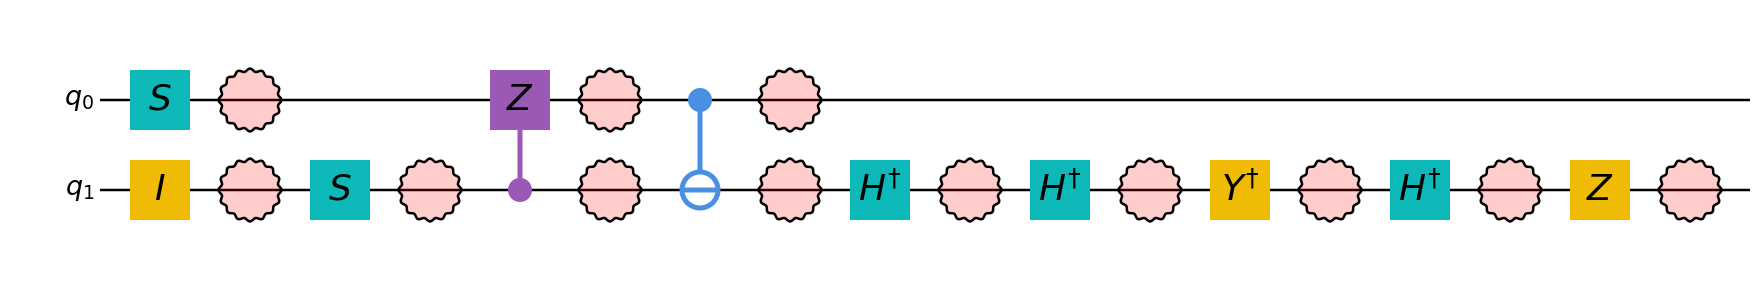

d=3

samples_pf shape: (10000, 2)
first 5 samples:
 [[2 1]
 [0 1]
 [0 0]
 [0 2]
 [0 0]]
d=3: PF vs DM: max_err=5.5792e-04, L1=1.8882e-03, sum(est)=1.000000
close? True



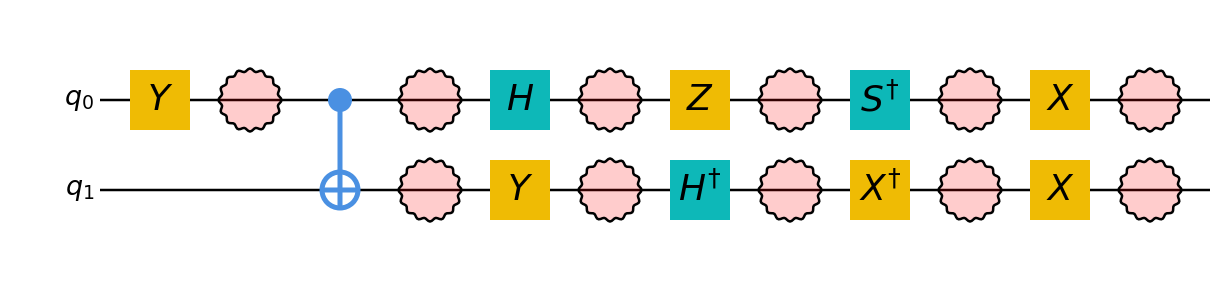

d=4

samples_pf shape: (10000, 2)
first 5 samples:
 [[3 3]
 [1 2]
 [3 3]
 [2 0]
 [3 0]]
d=4: PF vs DM: max_err=4.1400e-04, L1=2.7790e-03, sum(est)=1.000000
close? True



In [3]:
n = 2

for d, seed_circ, seed_pf in ([3, 123, 321], [4, 456, 654]):
    qc = qq.utils.random_circuit(n, d, max_size=10, max_depth=10, seed=seed_circ)
    p = 0.2
    qc.add_noise_global(p)
    qc.draw()
    print(f"d={d}\n")

    # Exact DM simulation
    rho = qc.execute_density_matrix()
    p_dm = qq.utils.density_matrix_to_probvector(rho)
    
    # Tableau sampling
    if d == 4:
        tab = qq.CompositeTableau(n, d, full=True)
    else:
        tab = qq.Tableau(n, d, full=True)
    tab.apply_circuit(qc)
    
    samples_pf = tab.sample_measurements_noisy_pf(qc, shots=10_000, seed=seed_pf)
    print("samples_pf shape:", samples_pf.shape)
    print("first 5 samples:\n", samples_pf[:5])
    
    # Estimate probability vector
    p_pf = tab.to_probvector_noisy_pf(qc, shots=2_000_000, seed=seed_pf)
    
    show_errors(p_dm, p_pf, f"d={d}: PF vs DM")
    print("close?", np.allclose(p_pf, p_dm, atol=1e-3, rtol=0))
    print()

## Custom noise model

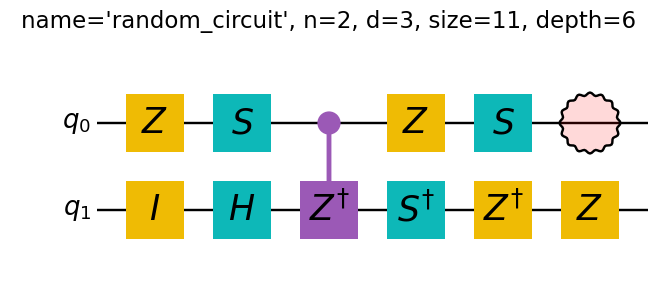

Custom model: (n=2, d=3) PF vs DM: max_err=2.7633e-04, L1=9.1633e-04, sum(est)=1.000000
close? True



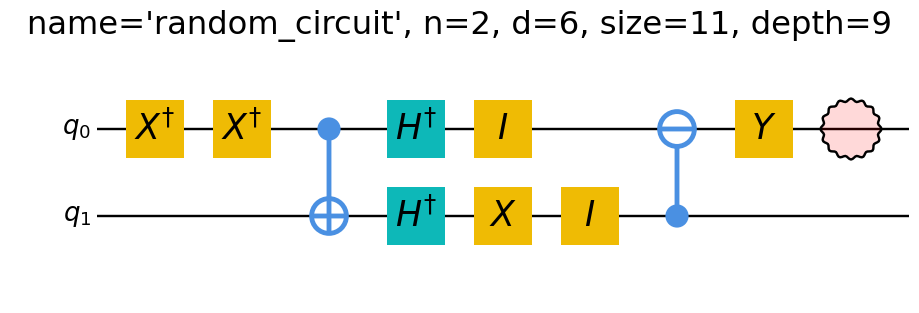

Custom model: (n=2, d=6) PF vs DM: max_err=2.6828e-04, L1=4.0456e-03, sum(est)=1.000000
close? True



In [4]:
def make_custom_weyl_model(d):
    P = np.zeros((d, d), dtype=float)
    P[0, 0] = 0.85  # identity
    P[1, 2] = 0.10  # X^1 Z^2
    P[2, 1] = 0.05  # X^2 Z^1
    return P

for (n, d, seed_circ, seed_pf) in [(2, 3, 11, 22), (2, 6, 33, 44)]:
    qc = qq.utils.random_circuit(n, d, max_size=10, max_depth=10, seed=seed_circ)

    P = make_custom_weyl_model(d)
    qc.add_noise_channel(qudit=0, noise_model=P)

    qc.draw(show_info=True, show_title=True)

    rho = qc.copy().execute_density_matrix()
    p_dm = qq.utils.density_matrix_to_probvector(rho)
    
    if d == 6:
        tab = qq.CompositeTableau(n, d, full=True)
    else:
        tab = qq.Tableau(n, d, full=True)
    tab.apply_circuit(qc)

    p_pf = tab.to_probvector_noisy_pf(qc, shots=2_000_000, seed=seed_pf)

    show_errors(p_dm, p_pf, f"Custom model: (n={n}, d={d}) PF vs DM")
    print("close?", np.allclose(p_pf, p_dm, atol=1e-2, rtol=0))
    print()

## Fidelity

**DM**

In [5]:
def state_fidelity_via_dm(qc_ideal, qc_noisy) -> float:
    qc_ideal_rev = qc_ideal.reverse(in_place=False)
    qc_sandwich = qc_noisy.compose(qc_ideal_rev, in_place=False)

    rho = qc_sandwich.execute_density_matrix()
    p = qq.utils.density_matrix_to_probvector(rho)
    return float(p[0])

for (n, d, seed_circ) in [(2, 3, 7), (2, 4, 8)]:
    qc_ideal = qq.utils.random_circuit(n, d, max_size=10, max_depth=10, seed=seed_circ)
    qc_noisy = qc_ideal.copy()
    qc_noisy.add_noise_global(0.2)

    F_dm = state_fidelity_via_dm(qc_ideal, qc_noisy)
    print(f"(n={n}, d={d}) state fidelity via DM:", F_dm)

def entanglement_fidelity_via_dm(qc_ideal, qc_noisy):
    n = qc_ideal.n
    d = qc_ideal.d

    qc_univ = qq.utils.univ_input_state_circuit(n, d)
    qc_univ_rev = qc_univ.reverse(in_place=False)
    qc_ideal_rev = qc_ideal.reverse(in_place=False)

    qc_sandwich = qc_univ.copy()
    qc_sandwich = qc_sandwich.compose(qc_noisy, in_place=False)
    qc_sandwich = qc_sandwich.compose(qc_ideal_rev, in_place=False)
    qc_sandwich = qc_sandwich.compose(qc_univ_rev, in_place=False)

    rho = qc_sandwich.execute_density_matrix()
    p = qq.utils.density_matrix_to_probvector(rho)
    return float(p[0])

for (n, d, seed_circ) in [(2, 3, 7), (2, 4, 8)]:
    qc_ideal = qq.utils.random_circuit(n, d, max_size=10, max_depth=10, seed=seed_circ)
    qc_noisy = qc_ideal.copy()
    qc_noisy.add_noise_global(0.2)

    F_dm_ent = entanglement_fidelity_via_dm(qc_ideal, qc_noisy)
    print(f"(n={n}, d={d}) entanglement fidelity via DM:", F_dm_ent)

(n=2, d=3) state fidelity via DM: 0.20322185925578112
(n=2, d=4) state fidelity via DM: 0.18296871217982646
(n=2, d=3) entanglement fidelity via DM: 0.06813037761509995
(n=2, d=4) entanglement fidelity via DM: 0.07773389143516533


**Tableau**

In [6]:
shots_fid = 200_000

for (n, d, seed_circ, seed_fid) in [(2, 3, 7, 100), (2, 4, 8, 200)]:
    qc_ideal = qq.utils.random_circuit(n, d, max_size=10, max_depth=10, seed=seed_circ)
    qc_noisy = qc_ideal.copy()
    qc_noisy.add_noise_global(0.2)

    # State fidelity on |0...0>
    F_mc_state = qq.utils.fidelity_np(qc_noisy, shots=shots_fid, entanglement_fidelity=False, seed=seed_fid)

    # Entanglement fidelity
    F_mc_ent = qq.utils.fidelity_np(qc_noisy, shots=shots_fid, entanglement_fidelity=True, seed=seed_fid + 1)

    print(f"(n={n}, d={d}) MC state fidelity:", F_mc_state)
    print(f"(n={n}, d={d}) MC entanglement fidelity:", F_mc_ent)
    print()

(n=2, d=3) MC state fidelity: 0.203285
(n=2, d=3) MC entanglement fidelity: 0.067425

(n=2, d=4) MC state fidelity: 0.18393
(n=2, d=4) MC entanglement fidelity: 0.07715



In [7]:
shots_fid = 300_000

for (n, d, seed_circ, seed_fid) in [(1, 3, 3, 10), (1, 6, 4, 20), (2, 3, 5, 30)]:
    qc_ideal = qq.utils.random_circuit(n, d, max_size=8, max_depth=8, seed=seed_circ)
    qc_noisy = qc_ideal.copy()
    qc_noisy.add_noise_global(0.2)

    F_dm = entanglement_fidelity_via_dm(qc_ideal, qc_noisy)
    F_mc = qq.utils.fidelity_np(qc_noisy, shots=shots_fid, entanglement_fidelity=True, seed=seed_fid)

    print(f"(n={n}, d={d}) F_ent DM={F_dm:.6f}, MC={F_mc:.6f}, max_abs_diff={abs(F_dm - F_mc):.4e}")

(n=1, d=3) F_ent DM=0.226792, MC=0.226057, max_abs_diff=7.3519e-04
(n=1, d=6) F_ent DM=0.181799, MC=0.180907, max_abs_diff=8.9198e-04
(n=2, d=3) F_ent DM=0.097956, MC=0.097933, max_abs_diff=2.2268e-05


**PF Fidelity**

In [8]:
shots_fid = 300_000

for (n, d, seed_circ, seed_fid) in [(1, 3, 3, 10), (1, 6, 4, 20), (2, 3, 5, 30)]:
    qc_ideal = qq.utils.random_circuit(n, d, max_size=8, max_depth=8, seed=seed_circ)
    qc_noisy = qc_ideal.copy()
    qc_noisy.add_noise_global(0.2)

    F_dm = entanglement_fidelity_via_dm(qc_ideal, qc_noisy)
    F_mc = qq.utils.fidelity_pf(qc_noisy, shots=shots_fid, entanglement_fidelity=True, seed=seed_fid)

    print(f"(n={n}, d={d}) F_ent DM={F_dm:.6f}, MC={F_mc:.6f}, max_abs_diff={abs(F_dm - F_mc):.4e}")

(n=1, d=3) F_ent DM=0.226792, MC=0.226283, max_abs_diff=5.0853e-04
(n=1, d=6) F_ent DM=0.181799, MC=0.181027, max_abs_diff=7.7198e-04
(n=2, d=3) F_ent DM=0.097956, MC=0.097933, max_abs_diff=2.2268e-05
